# Crop and Mixup experiment review
Author / Kaggle team: **Zihan Xu**. [Public repository](https://github.com/Zihan-Xu/DL-project1).

## tl;dr
All 6 registered runs completed 80 epochs and passed independent CPU replay. Selected single-branch recipe: **crop_mixup/tta, 95.7800%** validation mean across seeds 142-144. It does not exceed the previous 240-epoch recipe's 96.04% mean.

The fixed dual-residual candidate achieved **96.3333%** across all three seeds, with **4,872,692 total parameters**; its recommendation criterion passed: **True**. This is local validation on a reused split. New Kaggle accuracy is unavailable. Latest previous-model score: **0.87900, user reported**.

## Context & Methods
This review recomputes prediction counts, confirms model size, checks final training logs and CSV hashes, and visualizes results. It does not retrain or use hidden test labels.

### Key Assumptions
All research seeds share the same repeatedly used 5k validation set. Each research checkpoint is the best raw-validation epoch; final deployment fixes seed 42 and uses the last of 80 epochs on all 50k. Error bars below are seed SD, not independent-data confidence intervals. Final training consumes the former local holdouts.

## Data
Six new 80-epoch runs, three reused 80-epoch controls, one final 50k fit, three matched-seed dual-model replays and four distinct CSV alternatives. Original logs, saved predictions and verification records are under `evidence/`.


In [1]:
from pathlib import Path
import csv, hashlib, json, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
TASK=Path.cwd()
if not (TASK/'evidence/study_DECISION.json').exists():
    TASK=Path('tasks/2026-11-06_crop_mixup_sprint_v3').resolve()
sys.path.insert(0,str(TASK/'code'))
import operators
read=lambda p:json.loads(p.read_text(encoding='utf-8-sig'))
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
decision=read(TASK/'evidence/study_DECISION.json')
comparison=read(TASK/'evidence/study_COMPARISON.json')
summary=pd.DataFrame(comparison['summaries'])
history=pd.read_csv(TASK/'evidence/history.csv')
versions=read(TASK/'evidence/submission_versions.json')
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})


## Results
### Verify complete research evidence

In [2]:
recomputed=[]
for run in read(TASK/'evidence/study_manifest.json')['runs']:
    folder=TASK/'evidence/research_logs'/run['run_id']
    logs=pd.read_csv(folder/'history.csv'); assert logs.epoch.tolist()==list(range(1,81))
    saved=np.load(folder/'inference.npz'); evidence=read(folder/'audit_cpu.json')
    assert evidence['passed'] and evidence['n']==5000
    for policy,key in [('raw','raw_logits'),('tta','tta_probabilities')]:
        correct=int((saved[key].argmax(1)==saved['labels']).sum())
        assert correct==evidence[policy+'_correct']
        recomputed.append(dict(configuration=run['spec']['name'],seed=run['seed'],policy=policy,correct=correct))
computed=pd.DataFrame(recomputed)
for row in summary.itertuples():
    if row.configuration=='control':
        counts=[]
        for seed in [142,143,144]:
            name='validation_predictions.csv' if row.policy=='raw' else 'tta_predictions.csv'
            frame=pd.read_csv(TASK/'evidence/research_logs'/f'confirm_000_seed{seed}'/name)
            truth=frame['label'] if 'label' in frame else frame['true_label']
            pred=frame['prediction'] if 'prediction' in frame else frame['predicted_label']
            counts.append(int((truth==pred).sum()))
    else:counts=computed[(computed.configuration==row.configuration)&(computed.policy==row.policy)].correct.tolist()
    assert len(counts)==3 and abs(np.mean(counts)/5000-row.mean_accuracy)<1e-12
print('Verified all 6 new runs, all 3 controls and all 6 three-seed means.')
display(summary[['configuration','policy','n','mean_accuracy','sd']].assign(mean_accuracy=lambda d:d.mean_accuracy*100,sd=lambda d:d.sd*100).rename(columns={'mean_accuracy':'mean_percent','sd':'seed_SD_pp'}).round(4))


Verified all 6 new runs, all 3 controls and all 6 three-seed means.


,configuration,policy,n,mean_percent,seed_SD_pp
0,control,raw,3,94.8267,0.1553
1,control,tta,3,95.2333,0.1332
2,crop,raw,3,95.2200,0.1114
3,crop,tta,3,95.6600,0.1833
4,crop_mixup,raw,3,95.4667,0.1665
5,crop_mixup,tta,3,95.7800,0.0872


### Compare the complete three-seed means
Focused accuracy scale; identical80-epoch budgets. Error bars show seed SD.

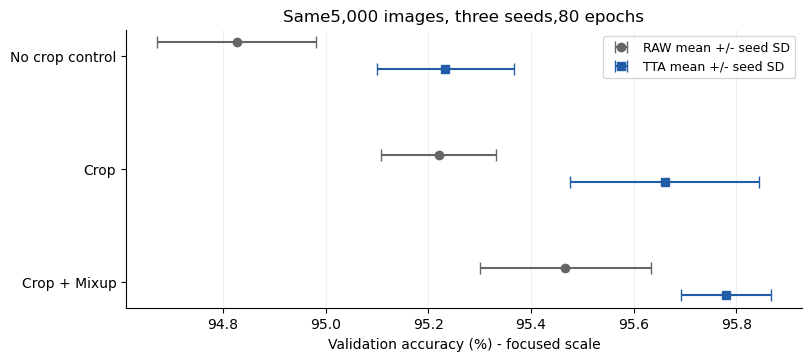

,Comparison,Policy,Mean delta (pp),Paired 95% interval (pp),Holm p
0,crop - control,raw,0.3933,"[-0.1994, 0.9861]",0.3117
1,crop - control,tta,0.4267,"[-0.3531, 1.2064]",0.3117
2,crop_mixup - control,raw,0.6400,"[-0.1345, 1.4145]",0.2832
3,crop_mixup - control,tta,0.5467,"[0.2159, 0.8775]",0.1153
4,crop_mixup - crop,raw,0.2467,"[0.0459, 0.4475]",0.1699
5,crop_mixup - crop,tta,0.1200,"[-0.3987, 0.6387]",0.4244


In [3]:
fig,ax=plt.subplots(figsize=(8,3.5),layout='constrained')
names=['control','crop','crop_mixup'];positions=np.arange(3)
for policy,offset,color,marker in [('raw',-.12,'#666666','o'),('tta',.12,'#225EA8','s')]:
    data=summary[summary.policy==policy].set_index('configuration').loc[names]
    ax.errorbar(data.mean_accuracy*100,positions+offset,xerr=data.sd*100,fmt=marker,color=color,capsize=4,label=policy.upper()+' mean +/- seed SD')
ax.set_yticks(positions,['No crop control','Crop','Crop + Mixup']);ax.invert_yaxis()
ax.set_xlabel('Validation accuracy (%) - focused scale');ax.set_title('Same5,000 images, three seeds,80 epochs')
ax.grid(axis='x',alpha=.2);ax.legend(loc='best',fontsize=9)
fig.savefig(TASK/'figures/comparison.png',dpi=180);display(fig);plt.close(fig)
paired=pd.DataFrame(comparison['paired_comparisons'])
display(pd.DataFrame({'Comparison':paired.candidate+' - '+paired.reference,'Policy':paired.policy,'Mean delta (pp)':paired.mean_delta_pp.round(4),'Paired 95% interval (pp)':[f'[{lo:.4f}, {hi:.4f}]' for lo,hi in zip(paired.ci95_low_pp,paired.ci95_high_pp)],'Holm p':paired.p_holm_six_comparisons.round(4)}))


Paired comparisons use seeds 142-144. The six exploratory tests use Holm adjustment; the same validation split has been reused in earlier selection. The240-epoch incumbent is shown separately in the spreadsheet because its compute budget differs.

### Inspect training progression

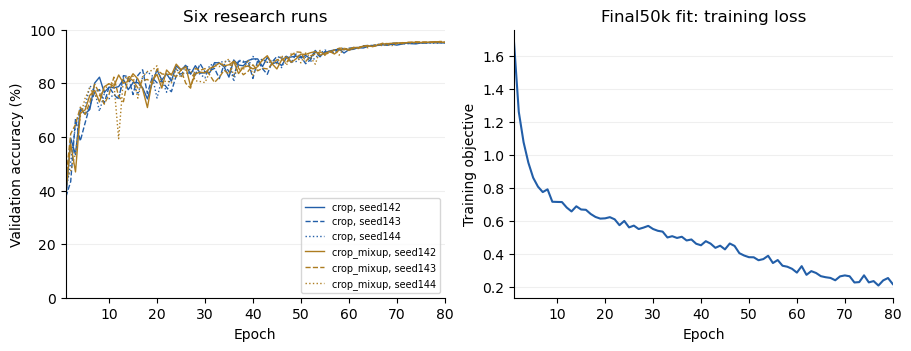

In [4]:
fig,axes=plt.subplots(1,2,figsize=(9,3.4),layout='constrained')
for cfg,color in [('crop','#225EA8'),('crop_mixup','#AD7C20')]:
    for seed,style in [(142,'-'),(143,'--'),(144,':')]:
        h=pd.read_csv(TASK/'evidence/research_logs'/f'{cfg}_seed{seed}'/'history.csv')
        axes[0].plot(h.epoch,h.validation_accuracy*100,color=color,ls=style,lw=1,label=f'{cfg}, seed{seed}')
axes[0].set(xlabel='Epoch',ylabel='Validation accuracy (%)',xlim=(1,80),ylim=(0,100),title='Six research runs')
axes[0].legend(fontsize=7,loc='lower right');axes[0].grid(axis='y',alpha=.2)
axes[1].plot(history.epoch,history.train_loss,color='#225EA8')
axes[1].set(xlabel='Epoch',ylabel='Training objective',xlim=(1,80),title='Final50k fit: training loss')
axes[1].grid(axis='y',alpha=.2)
fig.savefig(TASK/'figures/training.png',dpi=180);display(fig);plt.close(fig)


Training loss belongs to the prescribed final fit; it is not an independent test metric. Mixup changes the objective, so mixed-batch training accuracy is not used to rank recipes.

### Verify final model and submission choices

In [5]:
torch.set_num_threads(2)
cp=torch.load(TASK/'model.pt',map_location='cpu',weights_only=True)
net=operators.build(cp['recipe']);net.load_state_dict(cp['model_state'],strict=True)
parameters=sum(p.numel() for p in net.parameters())
assert parameters==2436346<=5000000 and cp['epoch']==80 and cp['training_images']==50000
assert history.epoch.tolist()==list(range(1,81)) and history.examples.eq(50000).all() and history.updates.eq(391).all()
sample=pd.read_csv(TASK/'evidence/sample_submission.csv',dtype={'id':str})
for v in versions:
    path=TASK/'submissions'/v['version']/'submission.csv';frame=pd.read_csv(path,dtype={'id':str})
    assert frame.columns.tolist()==['id','label'] and len(frame)==frame.id.nunique()==2000
    assert frame.id.tolist()==sample.id.tolist() and frame.label.between(0,9).all()
    assert sha(path)==v['csv_sha256']
assert len({v['csv_sha256'] for v in versions})==4
print('Trainable parameters:',parameters)
print('Final80-epoch model independent test / Kaggle accuracy: UNAVAILABLE')
print('Previous long_111/full50k/TTA Kaggle accuracy:87.90%, user reported; remote bytes unverified')
print('Verified4 distinct CSVs; new branch final training:',int(history.examples.sum()),'image presentations and',int(history.updates.sum()),'updates.')
display(pd.DataFrame(versions)[['version','policy','epochs','recommended','kaggle_score']])


Trainable parameters: 2436346
Final80-epoch model independent test / Kaggle accuracy: UNAVAILABLE
Previous long_111/full50k/TTA Kaggle accuracy:87.90%, user reported; remote bytes unverified
Verified4 distinct CSVs; new branch final training: 4000000 image presentations and 31280 updates.


,version,policy,epochs,recommended,kaggle_score
0,01_SELECTED_crop_mixup_full50k_tta,tta,80,False,NaN
1,02_ALTERNATIVE_crop_mixup_full50k_raw,raw,80,False,NaN
2,03_REFERENCE_long111_Kaggle087900,tta,240,False,0.879
3,00_RECOMMENDED_dual_residual_full50k,equal-weight new tta + reference tta,80 + 240,True,NaN


### Separately registered dual-residual experiment
Fixed equal probabilities, complete matched seeds, all parameters counted. The secondary plan was registered before any combination was evaluated. The old branch costs240 epochs and the new branch80; this is not a same-budget comparison.

Dual model total parameters: 4872692
Three-seed validation mean: 0.9633333333333334 ; seed SD: 0.00030550504633041625
Paired gain over long_111 (percentage points): 0.29333333333333333 ; 95% seed interval: [-0.12921355038661986, 0.7158802170532865]
All-seed recommendation criterion passed: True
Dual final-model independent test / Kaggle accuracy: UNAVAILABLE


,seed,old_correct,new_correct,combined_correct,n,passed
0,142,4803,4787,4818,5000,True
1,143,4794,4786,4817,5000,True
2,144,4809,4794,4815,5000,True


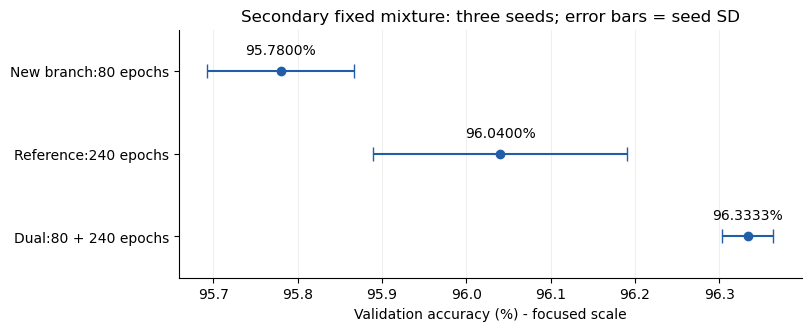

In [6]:
from dual_residual import DualResidual
dual=read(TASK/'evidence/ENSEMBLE_ACCEPTANCE.json')
assert dual['passed'] and dual['completed_verified']==3
replays=[]
for seed in [142,143,144]:
    record=read(TASK/'evidence'/f'ensemble_seed{seed}.json')
    path=TASK/'evidence'/f'ensemble_seed{seed}.npz';assert sha(path)==record['probabilities_sha256']
    saved=np.load(path);correct=int((saved['probabilities'].argmax(1)==saved['labels']).sum())
    assert correct==record['combined_correct'] and record['passed']
    replays.append(record)
assert abs(np.mean([r['combined_correct']/5000 for r in replays])-dual['mean_accuracy'])<1e-12
checkpoint=torch.load(TASK/'ensemble.pt',map_location='cpu',weights_only=True)
network=DualResidual(checkpoint['new_checkpoint'],checkpoint['reference_checkpoint'],checkpoint['new_policy'])
assert sum(p.numel() for p in network.parameters())==4872692<=5000000
assert checkpoint['mixture_weight']==.5
print('Dual model total parameters:',network.parameter_count)
print('Three-seed validation mean:',dual['mean_accuracy'],'; seed SD:',dual['sd'])
print('Paired gain over long_111 (percentage points):',dual['paired_delta_pp'],'; 95% seed interval:',dual['paired_ci95_pp'])
print('All-seed recommendation criterion passed:',dual['recommended'])
print('Dual final-model independent test / Kaggle accuracy: UNAVAILABLE')
display(pd.DataFrame(replays)[['seed','old_correct','new_correct','combined_correct','n','passed']])
fig,ax=plt.subplots(figsize=(8,3.2),layout='constrained')
for pos,(key,label) in enumerate([('new_correct','New branch:80 epochs'),('old_correct','Reference:240 epochs'),('combined_correct','Dual:80 + 240 epochs')]):
    values=np.array([r[key]/50 for r in replays]);mean=values.mean();sd=values.std(ddof=1)
    ax.errorbar(mean,pos,xerr=sd,fmt='o',color='#225EA8',capsize=5)
    ax.annotate(f'{mean:.4f}%',(mean,pos),xytext=(0,12),textcoords='offset points',ha='center')
ax.set_yticks(range(3),['New branch:80 epochs','Reference:240 epochs','Dual:80 + 240 epochs'])
ax.set_ylim(2.5,-.5);ax.set_xlabel('Validation accuracy (%) - focused scale')
ax.set_title('Secondary fixed mixture: three seeds; error bars = seed SD')
ax.grid(axis='x',alpha=.2);fig.savefig(TASK/'figures/dual_comparison.png',dpi=180);display(fig);plt.close(fig)


## Takeaways
The complete finite experiment selects **crop_mixup/tta**, mean **95.7800%**, as its new candidate. It does not exceed the earlier recipe's research mean; this does not establish a Kaggle improvement. Keep the user-reported0.87900 result distinct from local validation and from the new unscored CSVs.

The separately registered dual model scores **96.3333%**, with **4,872,692 total parameters**. Its all-seed recommendation criterion passed: **True**. Secondary selection and repeated validation use remain limitations; no official new score is available.

All planned runs and acceptance checks are complete. Crop and Mixup were actually run; CutMix/AugMix/RandAugment/new-WideResNet were deferred. The final80-epoch full50k model has no remaining independent local holdout. The official hidden score must come from an actual Kaggle evaluation.

References: [ResNet](https://arxiv.org/abs/1512.03385), [BlurPool](https://arxiv.org/abs/1904.11486), [Cutout](https://arxiv.org/abs/1708.04552), [Mixup](https://arxiv.org/abs/1710.09412).